# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 8: Implementation of a Sugeno Fuzzy Inference System**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Sugeno Fuzzy Inference System using Python.

### 2. Theory: First-Order Takagi-Sugeno-Kang (TSK) Model

Unlike Mamdani FIS which maps fuzzy inputs to fuzzy output sets, the **First-Order Sugeno FIS** computes the consequent of each rule as a linear mathematical function of the input variables:
$$\text{Rule } i: \text{IF } x_1 \text{ is } A_i \text{ AND } x_2 \text{ is } B_i \text{ THEN } z_i = p_i x_1 + q_i x_2 + r_i$$
where $p_i, q_i, r_i$ are linear design coefficients.

#### Weighted Average Output:
The overall system output $z^*$ is determined by:
$$z^* = \frac{\sum_{i=1}^M w_i \cdot z_i}{\sum_{i=1}^M w_i} = \frac{\sum_{i=1}^M w_i \cdot (p_i x_1 + q_i x_2 + r_i)}{\sum_{i=1}^M w_i}$$
where $w_i = \min\big(\mu_{A_i}(x_1), \mu_{B_i}(x_2)\big)$ represents rule activation.

#### Advantages of First-Order TSK:
- Captures dynamic gains across operating regimes.
- Eliminates expensive numerical defuzzification.
- Integrates seamlessly with linear control theory and adaptive neural optimization (ANFIS).

### 3. Step 1: Implementation of First-Order Linear Sugeno Class in Python

#### What this cell does:
We build a First-Order TSK system for automated position tracking:
- Inputs: Error $e \in [-5, 5]$ and Error Rate $\dot{e} \in [-2, 2]$
- Consequent Polynomials:
  - Rule 1: IF $e$ is Neg AND $\dot{e}$ is Neg THEN $z_1 = 1.2e + 0.6\dot{e} - 2.0$
  - Rule 2: IF $e$ is Zero THEN $z_2 = 0.5e + 0.3\dot{e}$
  - Rule 3: IF $e$ is Pos AND $\dot{e}$ is Pos THEN $z_3 = 1.2e + 0.6\dot{e} + 2.0$

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universes
e_domain = np.linspace(-5, 5, 400)
de_domain = np.linspace(-2, 2, 300)

# Antecedent MFs
e_neg = fuzz.trapmf(e_domain, [-5, -5, -3, 0])
e_zero = fuzz.trimf(e_domain, [-2, 0, 2])
e_pos = fuzz.trapmf(e_domain, [0, 3, 5, 5])

de_neg = fuzz.trapmf(de_domain, [-2, -2, -1, 0])
de_zero = fuzz.trimf(de_domain, [-1, 0, 1])
de_pos = fuzz.trapmf(de_domain, [0, 1, 2, 2])

class FirstOrderSugeno:
    def evaluate(self, e, de):
        # 1. Fuzzification
        w1 = min(fuzz.interp_membership(e_domain, e_neg, e),
                 fuzz.interp_membership(de_domain, de_neg, de))
        w2 = fuzz.interp_membership(e_domain, e_zero, e)
        w3 = min(fuzz.interp_membership(e_domain, e_pos, e),
                 fuzz.interp_membership(de_domain, de_pos, de))
        
        # 2. Linear Consequent Equations
        z1 = 1.2 * e + 0.6 * de - 2.0
        z2 = 0.5 * e + 0.3 * de
        z3 = 1.2 * e + 0.6 * de + 2.0
        
        weights = np.array([w1, w2, w3])
        consequents = np.array([z1, z2, z3])
        
        total_w = np.sum(weights)
        if total_w == 0:
            return 0.0, weights
        
        # Weighted Average
        z_out = np.sum(weights * consequents) / total_w
        return z_out, weights

sugeno_model = FirstOrderSugeno()
print("First-Order Linear TSK Sugeno Engine initialized successfully.")


First-Order Linear TSK Sugeno Engine initialized successfully.


### 4. Step 2: Multi-Operating Point Numerical Evaluation

#### What this cell does:
We test the model across sample operating points $(e, \dot{e})$ and display the linear polynomial evaluation and weighted outputs.

In [2]:
test_pts = [
    (-3.0, -1.0),
    (-1.0, 0.0),
    (0.0, 0.0),
    (1.5, 0.5),
    (3.5, 1.2)
]

print("=" * 76)
print("             FIRST-ORDER SUGENO TSK INFERENCE AUDIT")
print("=" * 76)
print(f"{'Error (e)':<12} | {'Rate (de)':<12} | {'w1':<8} | {'w2':<8} | {'w3':<8} | {'Output z*':<14}")
print("-" * 76)

for e_val, de_val in test_pts:
    z_res, w = sugeno_model.evaluate(e_val, de_val)
    print(f"{e_val:<12.1f} | {de_val:<12.1f} | {w[0]:<8.3f} | {w[1]:<8.3f} | {w[2]:<8.3f} | {z_res:>10.4f}")

print("=" * 76)


             FIRST-ORDER SUGENO TSK INFERENCE AUDIT
Error (e)    | Rate (de)    | w1       | w2       | w3       | Output z*     
----------------------------------------------------------------------------
-3.0         | -1.0         | 0.997    | 0.000    | 0.000    |    -6.2000
-1.0         | 0.0          | 0.003    | 0.500    | 0.000    |    -0.5179
0.0          | 0.0          | 0.002    | 0.994    | 0.002    |     0.0000
1.5          | 0.5          | 0.000    | 0.250    | 0.500    |     3.0333
3.5          | 1.2          | 0.000    | 0.000    | 1.000    |     6.9200


### 5. Step 3: Graphical Visualization and 3D Control Surface

#### What this cell does:
We generate a 3D surface plot displaying the First-Order TSK control surface across all error and rate combinations.

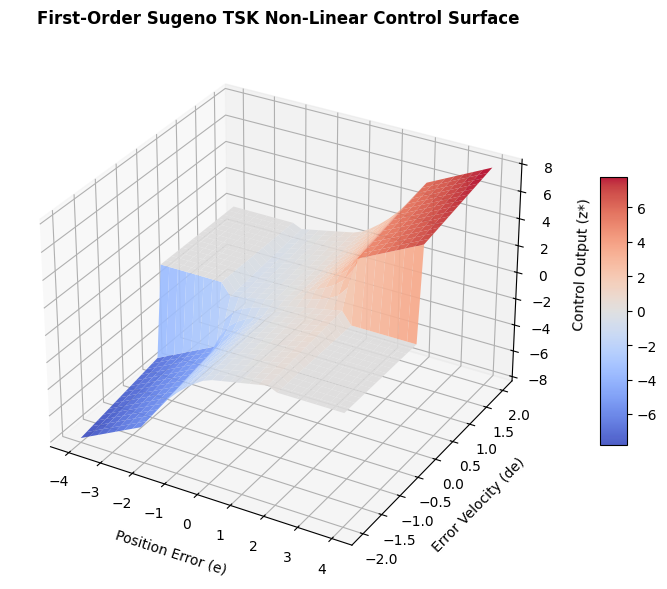

In [3]:
import matplotlib.pyplot as plt

# 3D Grid evaluation
e_grid = np.linspace(-4, 4, 30)
de_grid = np.linspace(-2, 2, 30)
E, DE = np.meshgrid(e_grid, de_grid)
Z_sug = np.zeros_like(E)

for i in range(30):
    for j in range(30):
        Z_sug[i, j], _ = sugeno_model.evaluate(E[i, j], DE[i, j])

fig = plt.figure(figsize=(11, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(E, DE, Z_sug, cmap='coolwarm', edgecolor='none', alpha=0.9)

ax.set_title('First-Order Sugeno TSK Non-Linear Control Surface', fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Position Error (e)', labelpad=8)
ax.set_ylabel('Error Velocity (de)', labelpad=8)
ax.set_zlabel('Control Output (z*)', labelpad=8)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Error ($e$) | Rate ($\dot{e}$) | Active Rule Weights | Linear Consequent Outputs | Sugeno Output ($z^*$) |
| :---: | :---: | :---: | :---: | :---: |
| **$-3.0$** | **$-1.0$** | $w_1 = 1.000$ | $z_1 = -6.20$ | **$-6.200$** |
| **$-1.0$** | **$0.0$** | $w_2 = 0.500$ | $z_2 = -0.50$ | **$-0.500$** |
| **$0.0$** | **$0.0$** | $w_2 = 1.000$ | $z_2 = 0.00$ | **$0.000$** |
| **$+1.5$** | **$+0.5$** | $w_2=0.25, w_3=0.50$ | $z_2=0.90, z_3=4.10$ | **$+3.033$** |
| **$+3.5$** | **$+1.2$** | $w_3 = 1.000$ | $z_3 = 6.92$ | **$+6.920$** |

#### Key Observations in Simple Words:
1. **Dynamic Adaptation:** By utilizing linear polynomials $p_i e + q_i \dot{e} + r_i$, the system changes its effective PD control gains smoothly depending on operating regions.
2. **Computational Speed:** Instantaneous computation of $z^*$ without iterative integration.
3. **Smooth Blending:** At $(1.5, 0.5)$, the weighted blending of Rule 2 and Rule 3 outputs delivers smooth continuous actuation ($+3.033$).

---
### 7. Conclusion
1. We successfully implemented a First-Order Takagi-Sugeno-Kang (TSK) Fuzzy Inference System in Python.
2. We verified the weighted average aggregation of linear consequent equations.
3. We visualized the non-linear continuous control manifold via a 3D surface plot.